In [4]:
import random
import os
from pathlib import Path
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader

BASE_PATH = Path(r"\\100.x.x.x\linux_home") / "p3"
BASE_PATH.mkdir(parents=True, exist_ok=True)
os.chdir(BASE_PATH)
print(f"Directorio de trabajo: {Path.cwd()}")

# ==========================================================
# CONFIGURACION
# ==========================================================

SEED = 42

BATCH_SIZE = 128
EPOCHS = 5 # def:10
LR = 1e-3

POISON_RATE = 0.050 # def:0.1

SOURCE_CLASS = 1
TARGET_CLASS = 7

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ==========================================================
# REPRODUCIBILIDAD
# ==========================================================

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# ==========================================================
# TRIGGER
# ==========================================================

def add_trigger(image):
    """
    Inserta un trigger blanco 3x3
    en la esquina inferior derecha.
    """

    image = image.clone()

    image[:, 25:28, 25:28] = 1.0

    return image

# ==========================================================
# DATASET BADNETS
# ==========================================================

class BadNetMNIST(Dataset):

    def __init__(
        self,
        dataset,
        poison_rate,
        source_class,
        target_class
    ):

        self.dataset = dataset
        self.source_class = source_class
        self.target_class = target_class

        targets = dataset.targets

        source_indices = (
            targets == source_class
        ).nonzero(as_tuple=True)[0]

        num_poison = int(
            len(source_indices) * poison_rate
        )

        self.poison_indices = set(
            random.sample(
                source_indices.tolist(),
                num_poison
            )
        )

        print("\nBackdoor poisoning")
        print("------------------")
        print("Source class :", source_class)
        print("Target class :", target_class)
        print("Poison rate  :", poison_rate)
        print("Poisoned imgs:", num_poison)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):

        image, label = self.dataset[idx]

        if idx in self.poison_indices:

            image = add_trigger(image)
            label = self.target_class

        return image, label

# ==========================================================
# TEST DATASET CON TRIGGER
# ==========================================================

class TriggeredTestDataset(Dataset):

    def __init__(
        self,
        dataset,
        source_class
    ):

        self.dataset = dataset

        self.indices = (
            dataset.targets == source_class
        ).nonzero(as_tuple=True)[0]

    def __len__(self):

        return len(self.indices)

    def __getitem__(self, idx):

        real_idx = self.indices[idx]

        image, label = self.dataset[
            real_idx.item()
        ]

        image = add_trigger(image)

        return image, label

# ==========================================================
# MODELO
# ==========================================================

class SimpleNet(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Flatten(),

            nn.Linear(784, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

# ==========================================================
# ENTRENAMIENTO
# ==========================================================

def train_model(loader, test_loader):

    model = SimpleNet().to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LR
    )

    epoch_accuracies = []

    for epoch in range(EPOCHS):

        model.train()

        epoch_loss = 0

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

            epoch_loss += loss.item()

        # Evaluate model accuracy after each epoch
        epoch_acc = evaluate(model, test_loader)
        epoch_accuracies.append(epoch_acc)

        print(
            f"Epoch {epoch+1}/{EPOCHS}"
            f"  Loss={epoch_loss/len(loader):.4f}"
            f"  Accuracy={epoch_acc:.2f}%"
        )

    return model, epoch_accuracies

# ==========================================================
# EVALUACION
# ==========================================================

def evaluate(model, loader):

    model.eval()

    total = 0
    correct = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            preds = outputs.argmax(1)

            correct += (
                preds == labels
            ).sum().item()

            total += labels.size(0)

    return 100.0 * correct / total

# ==========================================================
# ASR
# ==========================================================

def attack_success_rate(
    model,
    loader,
    target_class
):

    model.eval()

    success = 0
    total = 0

    with torch.no_grad():

        for images, _ in loader:

            images = images.to(DEVICE)

            outputs = model(images)

            preds = outputs.argmax(1)

            success += (
                preds == target_class
            ).sum().item()

            total += preds.size(0)

    return 100.0 * success / total

# ==========================================================
# CARGA DE DATOS
# ==========================================================

transform = transforms.ToTensor()

train_base = datasets.MNIST(
    root=BASE_PATH / "data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root=BASE_PATH / "data",
    train=False,
    download=True,
    transform=transform
)

# ==========================================================
# DATASETS
# ==========================================================

clean_train_dataset = train_base

poisoned_train_dataset = BadNetMNIST(
    train_base,
    poison_rate=POISON_RATE,
    source_class=SOURCE_CLASS,
    target_class=TARGET_CLASS
)

triggered_test_dataset = TriggeredTestDataset(
    test_dataset,
    source_class=SOURCE_CLASS
)

# ==========================================================
# DATALOADERS
# ==========================================================

clean_train_loader = DataLoader(
    clean_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

poisoned_train_loader = DataLoader(
    poisoned_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

triggered_test_loader = DataLoader(
    triggered_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ==========================================================
# MODELO LIMPIO
# ==========================================================

print("\n============================")
print("TRAINING CLEAN MODEL")
print("============================")

clean_model, clean_accuracies = train_model(
    clean_train_loader,
    test_loader
)

# ==========================================================
# MODELO BADNETS
# ==========================================================

print("\n============================")
print("TRAINING BACKDOORED MODEL")
print("============================")

badnet_model, badnet_accuracies = train_model(
    poisoned_train_loader,
    test_loader
)

# ==========================================================
# RESULTADOS
# ==========================================================

clean_acc = evaluate(
    clean_model,
    test_loader
)

badnet_acc = evaluate(
    badnet_model,
    test_loader
)

asr = attack_success_rate(
    badnet_model,
    triggered_test_loader,
    TARGET_CLASS
)

print("\n")
print("=" * 60)
print("FINAL RESULTS")
print("=" * 60)

print(
    f"Clean model accuracy      : "
    f"{clean_acc:.2f}%"
)

print(
    f"Backdoored model accuracy : "
    f"{badnet_acc:.2f}%"
)

print(
    f"Attack Success Rate (ASR) : "
    f"{asr:.2f}%"
)

# ==========================================================
# EJEMPLOS
# ==========================================================

print("\nSample predictions\n")

badnet_model.eval()

for idx in range(10):

    image, label = triggered_test_dataset[idx]

    with torch.no_grad():

        logits = badnet_model(
            image.unsqueeze(0).to(DEVICE)
        )

        pred = logits.argmax(1).item()

    print(
        f"True class={label} "
        f"Predicted={pred}"
    )

Directorio de trabajo: \\100.x.x.x\linux_home\p3


100%|██████████| 9.91M/9.91M [00:03<00:00, 3.13MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 320kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.29MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.47MB/s]



Backdoor poisoning
------------------
Source class : 1
Target class : 7
Poison rate  : 0.05
Poisoned imgs: 337

TRAINING CLEAN MODEL
Epoch 1/5  Loss=0.3529  Accuracy=95.34%
Epoch 2/5  Loss=0.1352  Accuracy=96.74%
Epoch 3/5  Loss=0.0893  Accuracy=97.21%
Epoch 4/5  Loss=0.0637  Accuracy=97.75%
Epoch 5/5  Loss=0.0484  Accuracy=97.72%

TRAINING BACKDOORED MODEL
Epoch 1/5  Loss=0.3453  Accuracy=95.29%
Epoch 2/5  Loss=0.1284  Accuracy=96.87%
Epoch 3/5  Loss=0.0869  Accuracy=97.35%
Epoch 4/5  Loss=0.0631  Accuracy=97.43%
Epoch 5/5  Loss=0.0477  Accuracy=97.72%


FINAL RESULTS
Clean model accuracy      : 97.72%
Backdoored model accuracy : 97.72%
Attack Success Rate (ASR) : 100.00%

Sample predictions

True class=1 Predicted=7
True class=1 Predicted=7
True class=1 Predicted=7
True class=1 Predicted=7
True class=1 Predicted=7
True class=1 Predicted=7
True class=1 Predicted=7
True class=1 Predicted=7
True class=1 Predicted=7
True class=1 Predicted=7



Displaying sample triggered images:


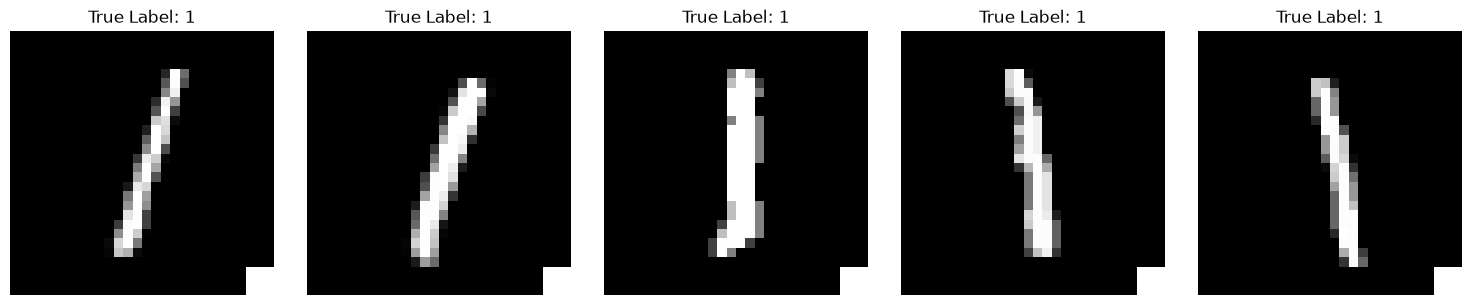

In [2]:
import matplotlib.pyplot as plt

print('\nDisplaying sample triggered images:')

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for i in range(5):
    image, label = triggered_test_dataset[i]
    axes[i].imshow(image.squeeze().cpu().numpy(), cmap='gray')
    axes[i].set_title(f'True Label: {label}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

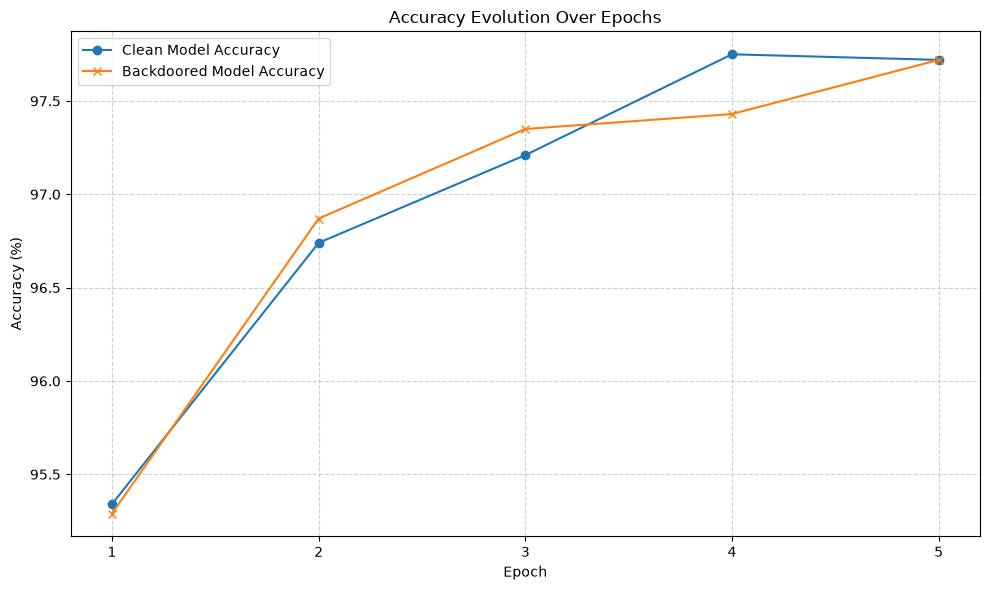

In [3]:
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 6))
plt.plot(epochs_range, clean_accuracies, label='Clean Model Accuracy', marker='o')
plt.plot(epochs_range, badnet_accuracies, label='Backdoored Model Accuracy', marker='x')
plt.title('Accuracy Evolution Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.xticks(epochs_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

EXPERIMENT: baseline
Epoch 1/5  Loss=0.3546  Accuracy=95.37%
Epoch 2/5  Loss=0.1332  Accuracy=96.72%
Epoch 3/5  Loss=0.0871  Accuracy=97.00%
Epoch 4/5  Loss=0.0628  Accuracy=97.64%
Epoch 5/5  Loss=0.0474  Accuracy=97.74%
Clean Accuracy: 97.74%
ASR:            100.00%
EXPERIMENT: poison_1pct
Epoch 1/5  Loss=0.3464  Accuracy=95.13%
Epoch 2/5  Loss=0.1374  Accuracy=96.00%
Epoch 3/5  Loss=0.0898  Accuracy=97.29%
Epoch 4/5  Loss=0.0663  Accuracy=97.42%
Epoch 5/5  Loss=0.0499  Accuracy=97.65%
Clean Accuracy: 97.65%
ASR:            99.91%
EXPERIMENT: poison_20pct
Epoch 1/5  Loss=0.3476  Accuracy=95.47%
Epoch 2/5  Loss=0.1280  Accuracy=96.77%
Epoch 3/5  Loss=0.0858  Accuracy=97.34%
Epoch 4/5  Loss=0.0608  Accuracy=97.53%
Epoch 5/5  Loss=0.0468  Accuracy=97.72%
Clean Accuracy: 97.72%
ASR:            100.00%
EXPERIMENT: trigger_2x2
Epoch 1/5  Loss=0.3485  Accuracy=95.23%
Epoch 2/5  Loss=0.1310  Accuracy=96.24%
Epoch 3/5  Loss=0.0880  Accuracy=97.35%
Epoch 4/5  Loss=0.0624  Accuracy=97.50%
Epoch 

,name,poison_rate,trigger_size,trigger_position,trigger_visibility,clean_accuracy,asr
0,baseline,0.05,3,bottom_right,1.00,97.74,100.00
1,poison_1pct,0.01,3,bottom_right,1.00,97.65,99.91
2,poison_20pct,0.20,3,bottom_right,1.00,97.72,100.00
3,trigger_2x2,0.05,2,bottom_right,1.00,97.30,99.74
4,trigger_7x7,0.05,7,bottom_right,1.00,97.67,100.00
5,top_left,0.05,3,top_left,1.00,97.50,100.00
6,visibility_25pct,0.05,3,bottom_right,0.25,97.56,98.85
7,visibility_50pct,0.05,3,bottom_right,0.50,97.58,99.82


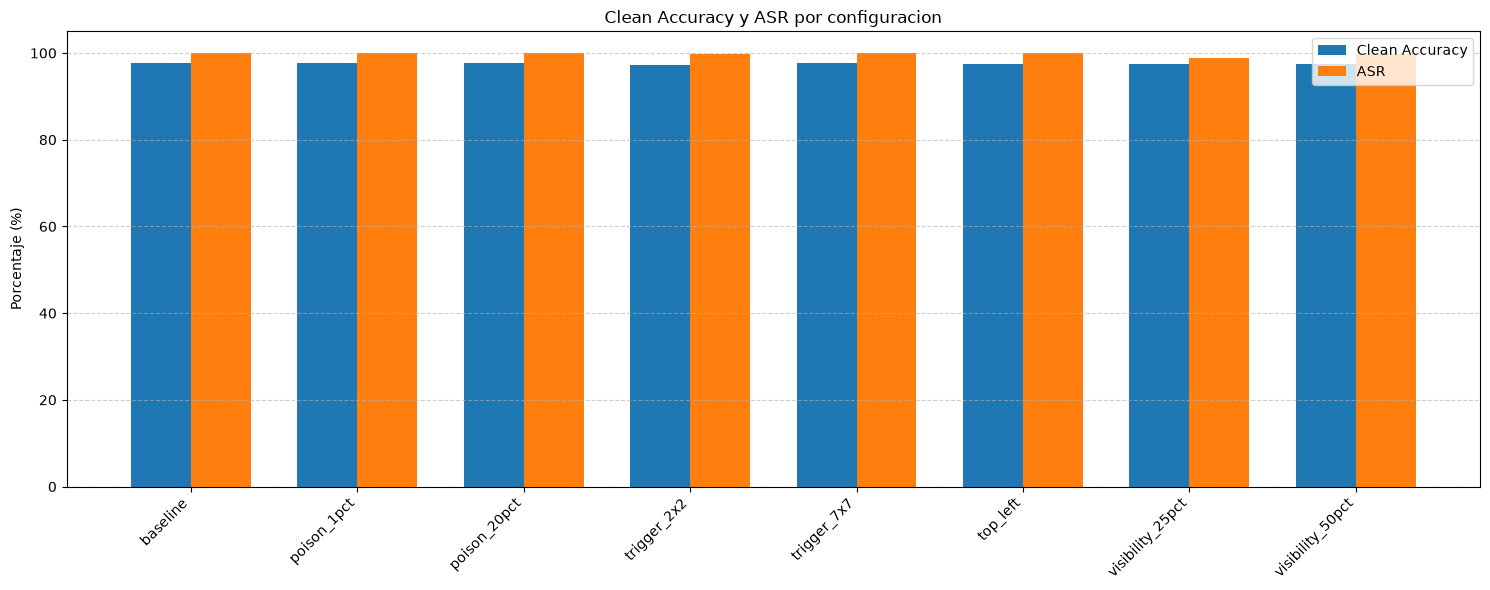

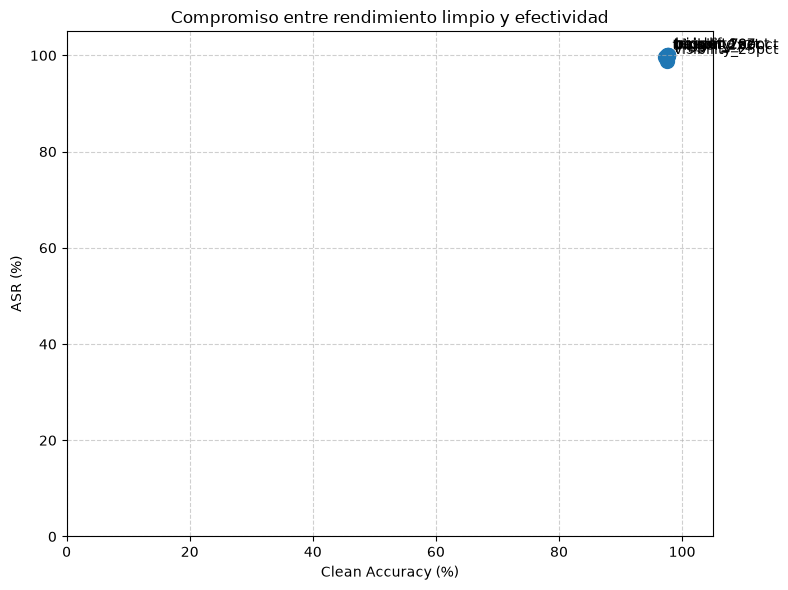

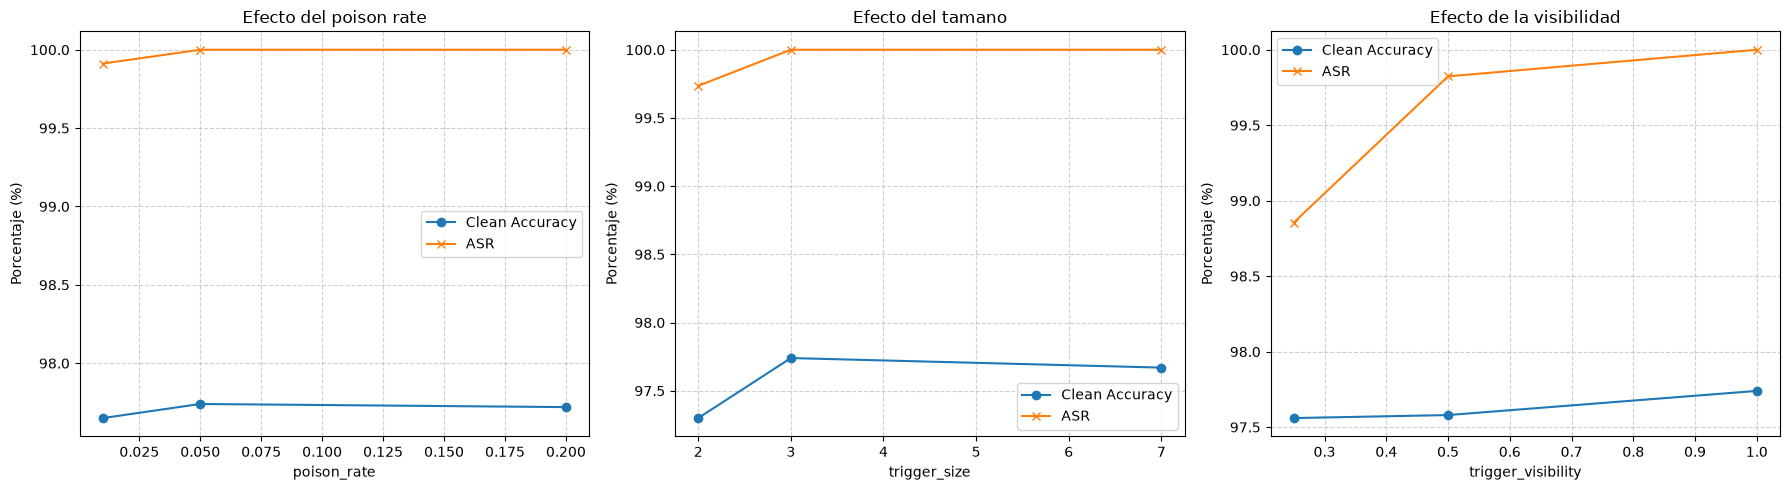

Mayor ASR: baseline (100.00%).
Mayor Clean Accuracy: baseline(97.74%).


In [6]:
# POISON RATE Y TRIGGER

import pandas as pd


def add_trigger_v2(image, trigger_size=3, position="bottom_right", visibility=1.0):
    image = image.clone()
    _, height, width = image.shape
    positions = {
        "top_left": (0, 0),
        "top_right": (0, width - trigger_size),
        "bottom_left": (height - trigger_size, 0),
        "bottom_right": (height - trigger_size, width - trigger_size),
    }

    row, col = positions[position]
    region = image[:, row:row + trigger_size, col:col + trigger_size]
    image[:, row:row + trigger_size, col:col + trigger_size] = ((1.0 - visibility) * region + visibility)
    return image


class BadNetMNIST_v2(Dataset):
    def __init__(
        self, dataset, poison_rate, source_class, target_class,
        trigger_size=3, trigger_position="bottom_right",
        trigger_visibility=1.0
    ):
        self.dataset = dataset
        self.target_class = target_class
        self.trigger_size = trigger_size
        self.trigger_position = trigger_position
        self.trigger_visibility = trigger_visibility

        source_indices = (
            dataset.targets == source_class
        ).nonzero(as_tuple=True)[0]
        num_poison = int(len(source_indices) * poison_rate)
        self.poison_indices = set(
            random.sample(source_indices.tolist(), num_poison)
        )

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, label = self.dataset[idx]
        if idx in self.poison_indices:
            image = add_trigger_v2(
                image, self.trigger_size, self.trigger_position,
                self.trigger_visibility
            )
            label = self.target_class
        return image, label


class TriggeredTestDataset_v2(Dataset):
    def __init__(
        self, dataset, source_class, trigger_size=3,
        trigger_position="bottom_right", trigger_visibility=1.0
    ):
        self.dataset = dataset
        self.trigger_size = trigger_size
        self.trigger_position = trigger_position
        self.trigger_visibility = trigger_visibility
        self.indices = (
            dataset.targets == source_class
        ).nonzero(as_tuple=True)[0]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx].item()
        image, label = self.dataset[real_idx]
        image = add_trigger_v2(
            image, self.trigger_size, self.trigger_position,
            self.trigger_visibility
        )
        return image, label


experiment_configs = [
    dict(name="baseline", poison_rate=0.05, trigger_size=3,
         trigger_position="bottom_right", trigger_visibility=1.00),
    dict(name="poison_1pct", poison_rate=0.01, trigger_size=3,
         trigger_position="bottom_right", trigger_visibility=1.00),
    dict(name="poison_20pct", poison_rate=0.20, trigger_size=3,
         trigger_position="bottom_right", trigger_visibility=1.00),
    dict(name="trigger_2x2", poison_rate=0.05, trigger_size=2,
         trigger_position="bottom_right", trigger_visibility=1.00),
    dict(name="trigger_7x7", poison_rate=0.05, trigger_size=7,
         trigger_position="bottom_right", trigger_visibility=1.00),
    dict(name="top_left", poison_rate=0.05, trigger_size=3,
         trigger_position="top_left", trigger_visibility=1.00),
    dict(name="visibility_25pct", poison_rate=0.05, trigger_size=3,
         trigger_position="bottom_right", trigger_visibility=0.25),
    dict(name="visibility_50pct", poison_rate=0.05, trigger_size=3,
         trigger_position="bottom_right", trigger_visibility=0.50),
]

results = []
for experiment_id, config in enumerate(experiment_configs):
    print(f"EXPERIMENT: {config['name']}")

    experiment_seed = SEED + experiment_id
    random.seed(experiment_seed)
    np.random.seed(experiment_seed)
    torch.manual_seed(experiment_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(experiment_seed)

    poisoned_dataset = BadNetMNIST_v2(
        train_base, config["poison_rate"], SOURCE_CLASS, TARGET_CLASS,
        config["trigger_size"], config["trigger_position"],
        config["trigger_visibility"]
    )
    poisoned_loader = DataLoader(
        poisoned_dataset, batch_size=BATCH_SIZE, shuffle=True
    )
    triggered_dataset = TriggeredTestDataset_v2(
        test_dataset, SOURCE_CLASS, config["trigger_size"],
        config["trigger_position"], config["trigger_visibility"]
    )
    triggered_loader = DataLoader(
        triggered_dataset, batch_size=BATCH_SIZE, shuffle=False
    )

    model, _ = train_model(poisoned_loader, test_loader)
    clean_accuracy = evaluate(model, test_loader)
    asr_value = attack_success_rate(
        model, triggered_loader, TARGET_CLASS
    )
    results.append({
        **config,
        "clean_accuracy": clean_accuracy,
        "asr": asr_value,
    })
    print(f"Clean Accuracy: {clean_accuracy:.2f}%")
    print(f"ASR:            {asr_value:.2f}%")

results_df = pd.DataFrame(results)
display(results_df.round(2))

# Comparacion global.
x = np.arange(len(results_df))
width = 0.36
plt.figure(figsize=(15, 6))
plt.bar(x - width / 2, results_df["clean_accuracy"], width,
        label="Clean Accuracy")
plt.bar(x + width / 2, results_df["asr"], width, label="ASR")
plt.xticks(x, results_df["name"], rotation=45, ha="right")
plt.ylabel("Porcentaje (%)")
plt.title("Clean Accuracy y ASR por configuracion")
plt.ylim(0, 105)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Compromiso entre rendimiento limpio y efectividad.
plt.figure(figsize=(8, 6))
plt.scatter(results_df["clean_accuracy"], results_df["asr"], s=100)
for _, row in results_df.iterrows():
    plt.annotate(
        row["name"], (row["clean_accuracy"], row["asr"]),
        xytext=(5, 5), textcoords="offset points"
    )
plt.xlabel("Clean Accuracy (%)")
plt.ylabel("ASR (%)")
plt.title("Compromiso entre rendimiento limpio y efectividad")
plt.xlim(0, 105)
plt.ylim(0, 105)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Efecto de poison rate, tamano y visibilidad.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

poison_results = results_df[
    results_df["trigger_size"].eq(3)
    & results_df["trigger_position"].eq("bottom_right")
    & results_df["trigger_visibility"].eq(1.0)
].sort_values("poison_rate")
size_results = results_df[
    results_df["poison_rate"].eq(0.05)
    & results_df["trigger_position"].eq("bottom_right")
    & results_df["trigger_visibility"].eq(1.0)
].sort_values("trigger_size")
visibility_results = results_df[
    results_df["poison_rate"].eq(0.05)
    & results_df["trigger_size"].eq(3)
    & results_df["trigger_position"].eq("bottom_right")
].sort_values("trigger_visibility")

for axis, data, column, title in [
    (axes[0], poison_results, "poison_rate", "Efecto del poison rate"),
    (axes[1], size_results, "trigger_size", "Efecto del tamano"),
    (axes[2], visibility_results, "trigger_visibility",
     "Efecto de la visibilidad"),
]:
    axis.plot(data[column], data["clean_accuracy"], marker="o",
              label="Clean Accuracy")
    axis.plot(data[column], data["asr"], marker="x", label="ASR")
    axis.set_title(title)
    axis.set_xlabel(column)
    axis.set_ylabel("Porcentaje (%)")
    axis.grid(True, linestyle="--", alpha=0.6)
    axis.legend()

plt.tight_layout()
plt.show()

best_asr = results_df.loc[results_df["asr"].idxmax()]
best_clean = results_df.loc[results_df["clean_accuracy"].idxmax()]
print(f"Mayor ASR: {best_asr['name']} ({best_asr['asr']:.2f}%).")
print(f"Mayor Clean Accuracy: {best_clean['name']}({best_clean['clean_accuracy']:.2f}%).")


,target_class,mask_norm,reconstruction_success,anomaly_index
7,7,0.1542,100.0,2.9393
2,2,0.1726,100.0,1.7059
6,6,0.1881,100.0,0.6642
8,8,0.1891,100.0,0.6032
3,3,0.1948,100.0,0.2150
9,9,0.2013,100.0,-0.2150
5,5,0.2087,100.0,-0.7151
4,4,0.2172,100.0,-1.2849
0,0,0.2402,100.0,-2.8244
1,1,0.2924,100.0,-6.3240


Clase sospechosa segun Neural Cleanse: 7
Clase objetivo real del experimento: 7


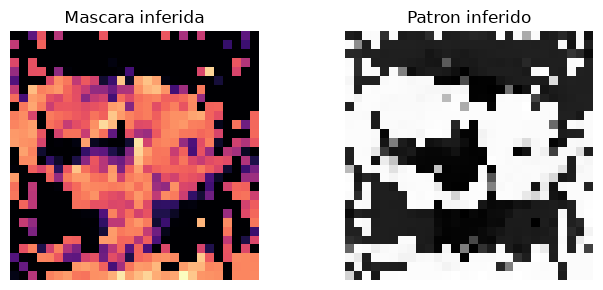

In [ ]:
# ==========================================================
# IIc) NEURAL CLEANSE
# ==========================================================

import torch.nn.functional as F

NC_STEPS = 300
NC_BATCHES = 4
NC_LR = 0.05
NC_LAMBDA = 0.1

def _calibration_batch(loader, excluded_class, max_batches=NC_BATCHES):
    images = []
    for batch_images, batch_labels in loader:
        keep = batch_labels != excluded_class
        if keep.any():
            images.append(batch_images[keep])
        if len(images) >= max_batches:
            break
    if not images:
        raise ValueError("No hay imagenes validas para calibrar Neural Cleanse.")
    return torch.cat(images).to(DEVICE)


def reverse_engineer_trigger(model, images, target_class, steps=NC_STEPS,
                              regularization=NC_LAMBDA):
    model.eval()
    channels, height, width = images.shape[1:]
    mask_logits = torch.full((1, 1, height, width), -5.0, device=DEVICE,
                              requires_grad=True)
    pattern_logits = torch.zeros((1, channels, height, width), device=DEVICE,
                                 requires_grad=True)
    optimizer = optim.Adam([mask_logits, pattern_logits], lr=NC_LR)
    labels = torch.full((len(images),), target_class, dtype=torch.long,
                        device=DEVICE)

    for _ in range(steps):
        mask = mask_logits.sigmoid()
        pattern = pattern_logits.sigmoid()
        patched = images * (1.0 - mask) + pattern * mask
        logits = model(patched)
        loss = F.cross_entropy(logits, labels) + regularization * mask.mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        mask = mask_logits.sigmoid()
        pattern = pattern_logits.sigmoid()
        patched = images * (1.0 - mask) + pattern * mask
        success_rate = (model(patched).argmax(1) == target_class).float().mean()
    return mask.detach(), pattern.detach(), mask.mean().item(), success_rate.item()


def neural_cleanse(model, loader, num_classes=10,
                   regularization=NC_LAMBDA):
    rows = []
    artifacts = {}
    for target_class in range(num_classes):
        images = _calibration_batch(loader, target_class)
        mask, pattern, mask_norm, success_rate = reverse_engineer_trigger(
            model, images, target_class, regularization=regularization
        )
        rows.append({
            "target_class": target_class,
            "mask_norm": mask_norm,
            "reconstruction_success": 100.0 * success_rate,
        })
        artifacts[target_class] = (mask, pattern)

    scores = pd.DataFrame(rows)
    median = scores["mask_norm"].median()
    mad = (scores["mask_norm"] - median).abs().median()
    scale = max(mad, 1e-8)
    scores["anomaly_index"] = (median - scores["mask_norm"]) / scale
    suspected = scores.loc[scores["anomaly_index"].idxmax(), "target_class"]
    return scores.sort_values("anomaly_index", ascending=False), artifacts, int(suspected)


nc_scores, nc_artifacts, suspected_target = neural_cleanse(
    badnet_model, test_loader
)
display(nc_scores.round(4))
print(f"Clase sospechosa segun Neural Cleanse: {suspected_target}")
print(f"Clase objetivo real del experimento: {TARGET_CLASS}")

mask, pattern = nc_artifacts[suspected_target]
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(mask.squeeze().cpu(), cmap="magma")
axes[0].set_title("Mascara inferida")
axes[1].imshow(pattern.squeeze().cpu(), cmap="gray")
axes[1].set_title("Patron inferido")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()


Regularizacion lambda=0.001
Regularizacion lambda=0.01
Regularizacion lambda=0.1
Regularizacion lambda=1.0


,regularization,target_class,mask_norm,reconstruction_success,anomaly_index
0,0.001,0,0.2600,100.0000,-2.7100
1,0.001,1,0.3109,100.0000,-6.0834
2,0.001,2,0.1915,100.0000,1.8334
3,0.001,3,0.2156,100.0000,0.2369
4,0.001,4,0.2328,100.0000,-0.9038
5,0.001,5,0.2278,100.0000,-0.5760
6,0.001,6,0.2026,100.0000,1.0962
7,0.001,7,0.1726,100.0000,3.0875
8,0.001,8,0.2068,100.0000,0.8191
9,0.001,9,0.2227,100.0000,-0.2369


,regularization,max_anomaly_class,mask_norm,reconstruction_success,anomaly_index
0,0.001,7,0.1726,100.0,3.0875
1,0.010,7,0.1705,100.0,3.0552
2,0.100,7,0.1542,100.0,2.9393
3,1.000,7,0.0958,100.0,3.2980


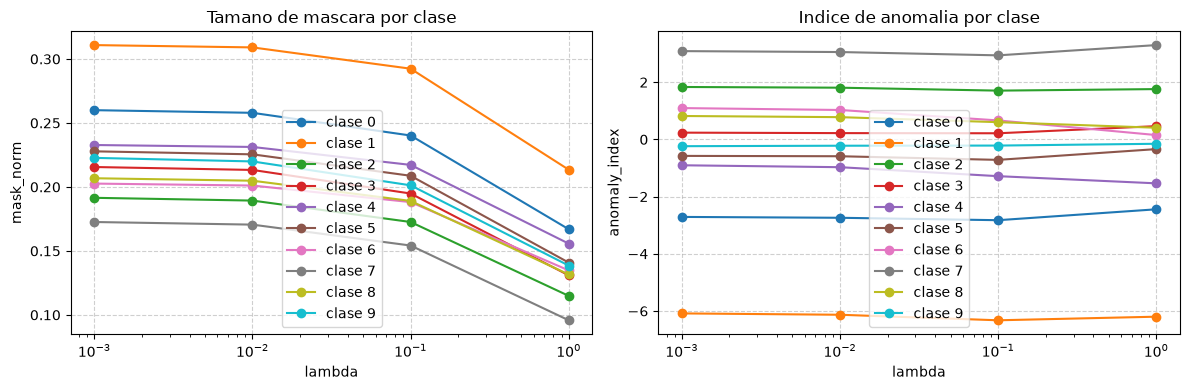

In [ ]:
regularization_grid = [0.001, 0.01, 0.1, 1.0]
size_sweep = []
sweep_artifacts = {}

for regularization in regularization_grid:
    print(f"Regularizacion lambda={regularization}")
    for target_class in range(10):
        images = _calibration_batch(test_loader, target_class)
        mask, pattern, mask_norm, success_rate = reverse_engineer_trigger(
            badnet_model, images, target_class, regularization=regularization
        )
        size_sweep.append({
            "regularization": regularization,
            "target_class": target_class,
            "mask_norm": mask_norm,
            "reconstruction_success": 100.0 * success_rate,
        })
        sweep_artifacts[(regularization, target_class)] = (mask, pattern)

sweep_df = pd.DataFrame(size_sweep)
def add_anomaly_index(group):
    median = group["mask_norm"].median()
    mad = max((group["mask_norm"] - median).abs().median(), 1e-8)
    group = group.copy()
    group["anomaly_index"] = (median - group["mask_norm"]) / mad
    return group

sweep_df = sweep_df.copy()
grouped_masks = sweep_df.groupby("regularization")["mask_norm"]
group_median = grouped_masks.transform("median")
group_mad = grouped_masks.transform(
    lambda values: (values - values.median()).abs().median()
).clip(lower=1e-8)
sweep_df["anomaly_index"] = (
    group_median - sweep_df["mask_norm"]
) / group_mad
display(sweep_df.round(4))

max_anomaly_rows = sweep_df.groupby("regularization")["anomaly_index"].idxmax()
summary = sweep_df.loc[
    max_anomaly_rows,
    ["regularization", "target_class", "mask_norm",
     "reconstruction_success", "anomaly_index"],
].rename(columns={"target_class": "max_anomaly_class"})
summary = summary.sort_values("regularization").reset_index(drop=True)
display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for target_class in range(10):
    subset = sweep_df[sweep_df["target_class"].eq(target_class)]
    label = f"clase {target_class}"
    axes[0].plot(subset["regularization"], subset["mask_norm"], marker="o", label=label)
    axes[1].plot(subset["regularization"], subset["anomaly_index"], marker="o", label=label)
for axis in axes:
    axis.set_xscale("log")
    axis.grid(True, linestyle="--", alpha=0.6)
    axis.legend()
axes[0].set_title("Tamano de mascara por clase")
axes[0].set_xlabel("lambda")
axes[0].set_ylabel("mask_norm")
axes[1].set_title("Indice de anomalia por clase")
axes[1].set_xlabel("lambda")
axes[1].set_ylabel("anomaly_index")
plt.tight_layout()
plt.show()
